# Membuat Data Splits json


In [2]:
import os
import shutil
import pandas as pd
import numpy as np
import json
from google.colab import drive

# 1. Sambungkan Google Drive ke Colab
drive.mount('/content/drive')

# 2. Buat folder data/raw sesuai Kontrak 1
os.makedirs('/content/data/raw', exist_ok=True)
os.makedirs('/content/data/hasil', exist_ok=True) # Sekalian buat folder hasil

# 3. Tentukan path file di Google Drive
path_drive_fd002 = '/content/drive/MyDrive/Praktikum MLN/Dataset ML/train_FD002.txt'
path_drive_fd004 = '/content/drive/MyDrive/Praktikum MLN/Dataset ML/train_FD004.txt'

# Copy file dari Drive ke folder lokal Colab (data/raw/)
shutil.copy(path_drive_fd002, '/content/data/raw/train_FD002.txt')
shutil.copy(path_drive_fd004, '/content/data/raw/train_FD004.txt')
print("File berhasil disalin dari Drive ke data/raw/")

# ==========================================
# PROSES PEMBUATAN SPLITS.JSON
# ==========================================

def get_unit_ids(filepath, prefix):
    # Baca CSV tanpa header, dipisah spasi
    df = pd.read_csv(filepath, sep=r'\s+', header=None)
    units = df[0].unique()
    return [f"{prefix}_{int(u)}" for u in units]

units_fd002 = get_unit_ids('/content/data/raw/train_FD002.txt', 'FD002')
units_fd004 = get_unit_ids('/content/data/raw/train_FD004.txt', 'FD004')

def split_60_20_20(unit_list, seed=42):
    np.random.seed(seed)
    shuffled = np.random.permutation(unit_list)
    n = len(shuffled)

    idx_a = int(0.6 * n)
    idx_b = int(0.8 * n)

    return {
        'A': shuffled[:idx_a].tolist(),
        'B': shuffled[idx_a:idx_b].tolist(),
        'C': shuffled[idx_b:].tolist()
    }

split_002 = split_60_20_20(units_fd002, seed=42)
split_004 = split_60_20_20(units_fd004, seed=42)

splits_final = {
    "seed": 42,
    "A": split_002['A'] + split_004['A'],
    "B": split_002['B'] + split_004['B'],
    "C": split_002['C'] + split_004['C']
}

# Simpan ke data/splits.json
with open('/content/data/splits.json', 'w') as f:
    json.dump(splits_final, f)

print("\nFile splits.json berhasil dibuat di folder /content/data/ !")
print(f"Jumlah Mesin -> Kelompok A: {len(splits_final['A'])}, B: {len(splits_final['B'])}, C: {len(splits_final['C'])}")

Mounted at /content/drive
File berhasil disalin dari Drive ke data/raw/

File splits.json berhasil dibuat di folder /content/data/ !
Jumlah Mesin -> Kelompok A: 305, B: 102, C: 102


## Melakukan Perhitungan Statistik dan K-Means untuk kelompok A
Berisi sensor yang konstan yaitu (s1, s5, s6, s10, s16, s18, s19)

=== Temuan EDA Kelompok A ===
Total Baris: 68291, Total Mesin: 305
Missing Values: 0
Duplikat: 0
Rata-rata umur mesin: 223.90 siklus



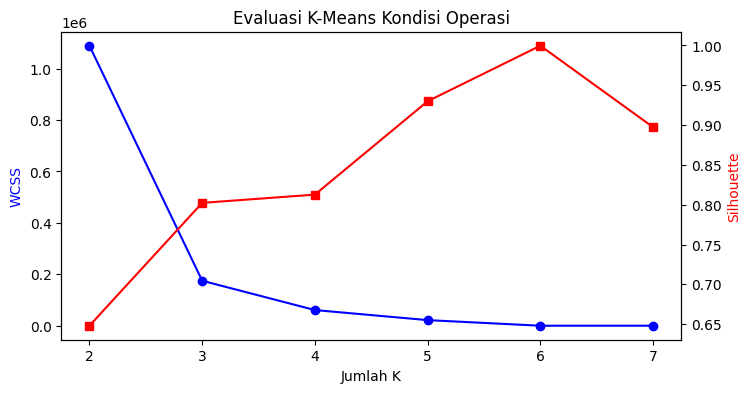


Sukses! 'kmeans_cond.joblib' dan 'norm_stats.json' berhasil disimpan di /models/v1/


In [3]:
import pandas as pd
import numpy as np
import json
import os
import joblib
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

# Buat folder models/v1/ sesuai kontrak
os.makedirs('/content/models/v1', exist_ok=True)

# 1. Definisikan Kolom dan Sensor Aktif
kolom = ['unit_asli', 'cycle', 'set1', 'set2', 'set3'] + [f's{i}' for i in range(1, 22)]
sensor_aktif = ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']

# 2. Fungsi Load Data dengan Prefix
def load_and_format(filepath, prefix):
    df = pd.read_csv(filepath, sep=r'\s+', header=None, names=kolom)
    df['unit'] = prefix + "_" + df['unit_asli'].astype(str)
    df = df.drop(columns=['unit_asli'])
    return df

# Gabungkan FD002 dan FD004
df_002 = load_and_format('/content/data/raw/train_FD002.txt', 'FD002')
df_004 = load_and_format('/content/data/raw/train_FD004.txt', 'FD004')
df_all = pd.concat([df_002, df_004], ignore_index=True)

# 3. Filter HANYA Kelompok A
with open('/content/data/splits.json', 'r') as f:
    splits = json.load(f)
df_A = df_all[df_all['unit'].isin(splits['A'])].copy()

# 4. EDA Dasar (Cek Missing, Duplikat, Panjang Umur)
print("=== Temuan EDA Kelompok A ===")
print(f"Total Baris: {len(df_A)}, Total Mesin: {df_A['unit'].nunique()}")
print(f"Missing Values: {df_A.isnull().sum().sum()}")
print(f"Duplikat: {df_A.duplicated().sum()}")
print(f"Rata-rata umur mesin: {df_A.groupby('unit')['cycle'].max().mean():.2f} siklus\n")

# 5. Buktikan K=6 dengan Elbow & Silhouette (Hanya pakai subset kecil agar cepat)
X_cond = df_A[['set1', 'set2', 'set3']]
X_sample = X_cond.sample(n=5000, random_state=42) # Sample untuk silhouette

wcss = []
silhouettes = []
k_range = range(2, 8)

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_sample)
    wcss.append(km.inertia_)
    silhouettes.append(silhouette_score(X_sample, labels))

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(k_range, wcss, 'bo-', label='WCSS (Elbow)')
ax1.set_xlabel('Jumlah K')
ax1.set_ylabel('WCSS', color='b')
ax2 = ax1.twinx()
ax2.plot(k_range, silhouettes, 'rs-', label='Silhouette Score')
ax2.set_ylabel('Silhouette', color='r')
plt.title('Evaluasi K-Means Kondisi Operasi')
plt.show()

# 6. Latih K-Means Akhir (K=6) dan Simpan Model
kmeans_final = KMeans(n_clusters=6, n_init=10, random_state=42)
df_A['kondisi'] = kmeans_final.fit_predict(X_cond)

# Simpan model K-Means ke models/v1/
joblib.dump(kmeans_final, '/content/models/v1/kmeans_cond.joblib')

# 7. Hitung Statistik Normalisasi Z-Score per Kondisi per Sensor Aktif
norm_stats = {}
for cond in range(6):
    norm_stats[int(cond)] = {}
    df_cond = df_A[df_A['kondisi'] == cond]
    for s in sensor_aktif:
        norm_stats[int(cond)][s] = {
            "mean": float(df_cond[s].mean()),
            "std": float(df_cond[s].std())
        }

# Simpan norm_stats.json ke models/v1/
with open('/content/models/v1/norm_stats.json', 'w') as f:
    json.dump(norm_stats, f, indent=2)

print("\nSukses! 'kmeans_cond.joblib' dan 'norm_stats.json' berhasil disimpan di /models/v1/")

Hasil silhouette bernilai 1.0 dan WCSS di angka 0.0 membuktikan bahwa 6 kondisi operasi pada dataset NASA C-MAPSS benar-benar terpisah secara sempurna dan diskrit. Ini sangat wajar karena variabel setting operasi pada data ini berupa setpoint yang tetap.

### Normalisasi data kelompok A
mengaplikasikan normalisasi Z-score tersebut ke data, menghitung fitur rata-rata 10 siklus terakhir ({s}_mean10), melakukan clustering tahap kesehatan (K=3), dan menyusun file kondisi.json

In [4]:
import joblib

# 1. Aplikasikan Normalisasi Z-Score per Kondisi
for cond in range(6):
    mask = df_A['kondisi'] == cond
    for s in sensor_aktif:
        mean_val = norm_stats[cond][s]['mean']
        std_val = norm_stats[cond][s]['std']
        df_A.loc[mask, f'{s}_norm'] = (df_A.loc[mask, s] - mean_val) / std_val

# 2. Buat Fitur Rata-rata 10 Siklus Terakhir ({s}_mean10)
kolom_mean10 = []
for s in sensor_aktif:
    nama_kolom = f'{s}_mean10'
    df_A[nama_kolom] = df_A.groupby('unit')[f'{s}_norm'].transform(lambda x: x.rolling(window=10, min_periods=1).mean())
    kolom_mean10.append(nama_kolom)

# 3. K-Means 3 Tahap Kesehatan
kmeans_health = KMeans(n_clusters=3, n_init=10, random_state=42)
df_A['cluster_kesehatan'] = kmeans_health.fit_predict(df_A[kolom_mean10])

# Simpan model tahap kesehatan
joblib.dump(kmeans_health, '/content/models/v1/health_kmeans.joblib')

# 4. Beri Nama Tahap Berdasarkan Rata-rata Siklus
# Cluster dengan siklus rata-rata terkecil = sehat, menengah = menurun, terbesar = kritis
rata_siklus = df_A.groupby('cluster_kesehatan')['cycle'].mean().sort_values()
label_map = {
    rata_siklus.index[0]: "sehat",
    rata_siklus.index[1]: "menurun",
    rata_siklus.index[2]: "kritis"
}
df_A['tahap'] = df_A['cluster_kesehatan'].map(label_map)

# 5. Siapkan Data untuk data/hasil/kondisi.json (Sesuai Kontrak 6)
# Ambil contoh 1 unit untuk data grafik sebelum/sesudah
unit_contoh = df_A['unit'].iloc[0]
df_contoh = df_A[df_A['unit'] == unit_contoh].head(2)

kondisi_json = {
    "k": 6,
    "centroid": kmeans_final.cluster_centers_.tolist(),
    "pemilihan_k": [
        {"k": k, "wcss": w, "silhouette": s}
        for k, w, s in zip(k_range, wcss, silhouettes)
    ],
    "sampel_titik": df_A[['set1', 'set2', 'set3', 'kondisi']].sample(n=2000, random_state=42).to_dict(orient='records'),
    "sebelum_sesudah": {
        "unit": unit_contoh,
        "sensor": "s11",
        "cycle": df_contoh['cycle'].tolist(),
        "mentah": df_contoh['s11'].tolist(),
        "normal": df_contoh['s11_norm'].tolist()
    },
    "kesehatan": {
        "k": 3,
        "urutan": ["sehat", "menurun", "kritis"],
        "silhouette": float(silhouette_score(df_A[kolom_mean10].sample(n=5000, random_state=42), df_A['cluster_kesehatan'].sample(n=5000, random_state=42))),
        "profil": df_A.groupby('tahap')[kolom_mean10].mean().reset_index().to_dict(orient='records'),
        "per_umur": []
    }
}

# 6. Validasi Proporsi Tahap Kesehatan (per 10% umur mesin)
# Kontrak meminta dihitung dari kelompok C, mari kita muat C sebentar untuk evaluasi ini
df_C = df_all[df_all['unit'].isin(splits['C'])].copy()
df_C['kondisi'] = kmeans_final.predict(df_C[['set1', 'set2', 'set3']])

for cond in range(6):
    mask = df_C['kondisi'] == cond
    for s in sensor_aktif:
        df_C.loc[mask, f'{s}_norm'] = (df_C.loc[mask, s] - norm_stats[cond][s]['mean']) / norm_stats[cond][s]['std']

for s in sensor_aktif:
    df_C[f'{s}_mean10'] = df_C.groupby('unit')[f'{s}_norm'].transform(lambda x: x.rolling(10, min_periods=1).mean())

df_C['cluster_kesehatan'] = kmeans_health.predict(df_C[kolom_mean10])
df_C['tahap'] = df_C['cluster_kesehatan'].map(label_map)
df_C['umur_maks'] = df_C.groupby('unit')['cycle'].transform('max')
df_C['persen_umur'] = np.ceil((df_C['cycle'] / df_C['umur_maks']) * 10) * 10

proporsi_umur = df_C.groupby(['persen_umur', 'tahap']).size().unstack(fill_value=0)
proporsi_umur = proporsi_umur.div(proporsi_umur.sum(axis=1), axis=0).reset_index()

for _, row in proporsi_umur.iterrows():
    kondisi_json["kesehatan"]["per_umur"].append({
        "persen_umur": int(row['persen_umur']),
        "sehat": round(row.get('sehat', 0), 2),
        "menurun": round(row.get('menurun', 0), 2),
        "kritis": round(row.get('kritis', 0), 2)
    })

# Simpan ke data/hasil/kondisi.json
with open('/content/data/hasil/kondisi.json', 'w') as f:
    json.dump(kondisi_json, f, indent=2)

print("Tugas Orang 1 selesai! File health_kmeans.joblib dan kondisi.json berhasil dibuat.")

Tugas Orang 1 selesai! File health_kmeans.joblib dan kondisi.json berhasil dibuat.


In [6]:
import os

# Buat folder engine agar tidak error
os.makedirs('/content/engine', exist_ok=True)

# 1. Isi engine/data.py
with open('/content/engine/data.py', 'w') as f:
    f.write("""import pandas as pd
import json
from .schema import KOLOM_ALL

def load_and_format(filepath, prefix):
    df = pd.read_csv(filepath, sep=r'\\s+', header=None, names=KOLOM_ALL)
    df['unit'] = prefix + "_" + df['unit_asli'].astype(str)
    df = df.drop(columns=['unit_asli'])
    return df

def load_splits(filepath='data/splits.json'):
    with open(filepath, 'r') as f:
        return json.load(f)
""")

# 2. Isi engine/conditions.py
with open('/content/engine/conditions.py', 'w') as f:
    f.write("""import json

def load_norm_stats(filepath='models/v1/norm_stats.json'):
    with open(filepath, 'r') as f:
        return json.load(f)

def apply_normalization(df, norm_stats, sensor_aktif):
    for cond in range(6):
        mask = df['kondisi'] == cond
        for s in sensor_aktif:
            kunci_cond = str(cond)
            if kunci_cond in norm_stats:
                mean_val = norm_stats[kunci_cond][s]['mean']
                std_val = norm_stats[kunci_cond][s]['std']
                df.loc[mask, f'{s}_norm'] = (df.loc[mask, s] - mean_val) / std_val
    return df
""")

# 3. Isi engine/health.py
with open('/content/engine/health.py', 'w') as f:
    f.write("""import joblib

def hitung_rolling_mean(df, sensor_aktif, window=10):
    kolom_mean = []
    for s in sensor_aktif:
        nama_kolom = f'{s}_mean{window}'
        df[nama_kolom] = df.groupby('unit')[f'{s}_norm'].transform(lambda x: x.rolling(window=window, min_periods=1).mean())
        kolom_mean.append(nama_kolom)
    return df, kolom_mean

def prediksi_tahap_kesehatan(df, kolom_mean, model_path='models/v1/health_kmeans.joblib'):
    kmeans_health = joblib.load(model_path)
    df['cluster_kesehatan'] = kmeans_health.predict(df[kolom_mean])
    return df
""")

print("Folder dan modul engine berhasil dibuat!")

Folder dan modul engine berhasil dibuat!
